| **Inicio**         | **atrás 2**                          | **Siguiente 4**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./1_2_Calculo_diferencial.ipynb) | [⏩](./1_4_Series.ipynb) |

# 1. INTEGRAL DEFINIDA

La integral definida:

$$
\boxed{
\int_a^b f(x)\,dx
}
$$

representa una **acumulación neta** entre $(a)$ y $(b)$.

Geométricamente, cuando $f(x)\geq0$, podemos interpretarla como el área bajo la curva.

Por ejemplo:

$$
\int_0^2x^2\,dx
$$

significa el área bajo:

$$
y=x^2
$$

entre:

$$
x=0
$$

y:

$$
x=2
$$

# 1.1 Cálculo a mano

Sabemos que:

$$
\int x^2dx=\frac{x^3}{3}+C
$$

Entonces:

$$
\int_0^2x^2dx
=
\left[\frac{x^3}{3}\right]_0^2
$$

$$
=
\frac{8}{3}-0
$$

$$
\boxed{\frac83}
$$

# 1.2 ¿Por qué aparece el área?

Imagina dividir el intervalo en pequeños rectángulos.

Si tenemos:

$$
\Delta x=\frac{b-a}{n}
$$

entonces aproximadamente:

$$
\int_a^b f(x)dx
\approx
\sum_{i=1}^{n}
f(x_i)\Delta x
$$

Cuando:

$$
n\rightarrow\infty
$$

obtenemos la integral.

Es decir:

$$
\boxed{
\text{integral}
=
\text{límite de sumas}
}
$$

Esto será importantísimo para integración numérica.

# 1.3 Python: visualizar rectángulos

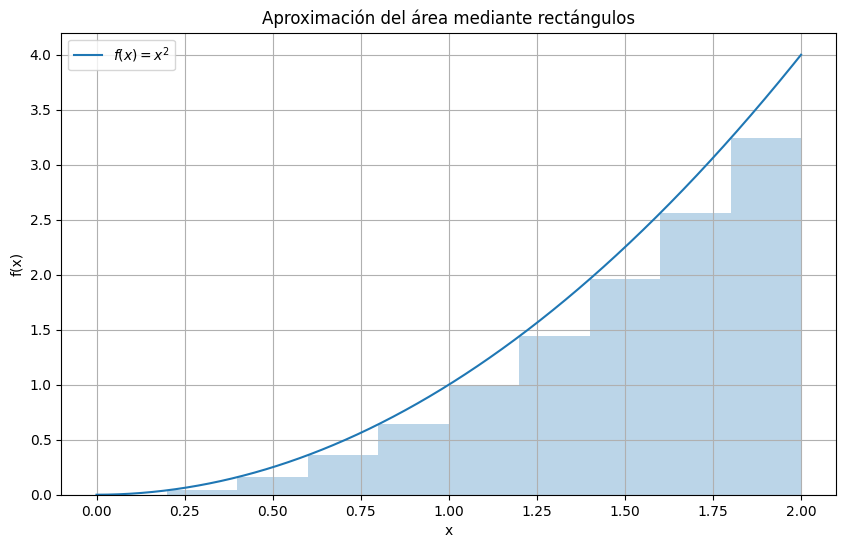

In [1]:
import numpy as np
import matplotlib.pyplot as plt

f = lambda x: x**2

a = 0
b = 2

x = np.linspace(a, b, 1000)
y = f(x)

plt.figure(figsize=(10, 6))

plt.plot(x, y, label=r"$f(x)=x^2$")

n = 10
dx = (b - a) / n

x_rect = np.linspace(a, b, n, endpoint=False)
y_rect = f(x_rect)

plt.bar(
    x_rect,
    y_rect,
    width=dx,
    alpha=0.3,
    align="edge"
)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Aproximación del área mediante rectángulos")
plt.grid(True)
plt.legend()

plt.show()

La idea matemática es:

$$
\sum f(x_i)\Delta x
$$

y al aumentar el número de rectángulos:

$$
\sum f(x_i)\Delta x
\rightarrow
\int_a^b f(x)dx
$$

# 1.4 Ejemplo más difícil

Considera:

$$
f(x)=e^{-x^2}
$$

Queremos:

$$
\int_{-2}^{2}e^{-x^2}dx
$$

Esta integral **no tiene una antiderivada elemental**.

Esto es importante.

No siempre podrás escribir:

$$
F(x)
$$

utilizando funciones elementales.

Aquí empieza a ser necesaria la computación científica.

# 1.5 Python

In [2]:
from scipy.integrate import quad
import numpy as np

f = lambda x: np.exp(-x**2)

resultado, error = quad(f, -2, 2)

print("Integral =", resultado)
print("Error estimado =", error)

Integral = 1.764162781524843
Error estimado = 1.958614141564776e-14


Obtendrás aproximadamente:

$$
1.76416
$$

Esto es un ejemplo perfecto de por qué necesitas **métodos numéricos** para SciML.

# 2. INTEGRAL INDEFINIDA

Una integral indefinida busca una función cuya derivada sea la función original.

Si:

$$
F'(x)=f(x)
$$

entonces:

$$
\boxed{
\int f(x)dx=F(x)+C
}
$$

# 2.1 Ejemplo

$$
\int 3x^2dx
$$

Buscamos una función cuya derivada sea:

$$
3x^2
$$

Tenemos:

$$
\boxed{x^3+C}
$$

porque:

$$
\frac{d}{dx}x^3=3x^2
$$

# 2.2 Ejemplo difícil

Consideremos:

$$
\int x^2e^x dx
$$

Aquí necesitamos **integración por partes**.

La fórmula:

$$
\boxed{
\int u\,dv
=
uv-\int v\,du
}
$$

Tomamos:

$$
u=x^2
$$

$$
dv=e^xdx
$$

Entonces:

$$
du=2xdx
$$

$$
v=e^x
$$

Por tanto:

$$
\int x^2e^xdx
=
x^2e^x-\int2xe^xdx
$$

Volvemos a aplicar integración por partes:

$$
\int xe^xdx
=
xe^x-e^x
$$

Entonces:

$$
\int x^2e^xdx
=
x^2e^x-2(xe^x-e^x)
$$

Finalmente:

$$
\boxed{
\int x^2e^xdx
=
e^x(x^2-2x+2)+C
}
$$

# 2.3 Comprobar con SymPy

In [4]:
import sympy as sp
x = sp.symbols("x")

f = x**2 * sp.exp(x)

integral = sp.integrate(f, x)

print(integral)

print(
    sp.simplify(
        sp.diff(integral, x) - f
    )
)

(x**2 - 2*x + 2)*exp(x)
0


El último resultado debería ser:

```text
0
```

Es decir:

$$
\frac{d}{dx}
\left[
e^x(x^2-2x+2)
\right]
=
x^2e^x
$$

# 3. TEOREMA FUNDAMENTAL DEL CÁLCULO

Este es probablemente **el concepto más importante de todo este bloque**.

Conecta derivadas e integrales.

Si:

$$
F(x)=\int_a^x f(t)dt
$$

entonces:

$$
\boxed{
F'(x)=f(x)
}
$$

En palabras:

> Si acumulas una función mediante una integral y luego derivás esa acumulación, recuperas la función original.

# 3.1 Ejemplo

Define:

$$
F(x)=\int_0^x t^2dt
$$

Sabemos que:

$$
F(x)=\frac{x^3}{3}
$$

Por tanto:

$$
F'(x)=x^2
$$

Es decir:

$$
\boxed{
\frac{d}{dx}
\left(
\int_0^x t^2dt
\right)
=x^2
}
$$

# 3.2 Segunda parte del teorema

Si $(F)$ es una antiderivada de $(f)$:

$$
F'(x)=f(x)
$$

entonces:

$$
\boxed{
\int_a^bf(x)dx
=
F(b)-F(a)
}
$$

Esto convierte un problema de área en un problema de evaluación.

# 3.3 Ejemplo físico

Supongamos que conoces la velocidad:

$$
v(t)=3t^2
$$

La posición recorrida entre $(t=0)$ y $(t=4)$ es:

$$
\Delta x=
\int_0^4v(t)dt
$$

Entonces:

$$
\Delta x=
\int_0^43t^2dt
$$

$$
=
[t^3]_0^4
$$

$$
=64
$$

Por tanto:

$$
\boxed{\Delta x=64}
$$

# 3.4 La idea que debes memorizar conceptualmente

$$
\boxed{
\text{derivada}
=
\text{tasa instantánea}
}
$$

$$
\boxed{
\text{integral}
=
\text{acumulación}
}
$$

Y:

$$
\boxed{
\text{integración y derivación son operaciones inversas}
}
$$

Esto aparecerá continuamente en SciML.

# 4. TÉCNICAS DE INTEGRACIÓN

Ahora viene una parte importante.

Debes aprender **cuándo utilizar cada técnica**.

# 4.1 Sustitución

Si tenemos:

$$
\int f(g(x))g'(x)dx
$$

podemos utilizar:

$$
u=g(x)
$$

## Ejemplo

$$
\int 2x\cos(x^2)dx
$$

Tomamos:

$$
u=x^2
$$

Entonces:

$$
du=2xdx
$$

La integral se transforma:

$$
\int\cos(u)du
$$

Por tanto:

$$
\boxed{
\sin(x^2)+C
}
$$

# 4.2 Python

In [5]:
x = sp.symbols("x")

f = 2*x*sp.cos(x**2)

resultado = sp.integrate(f, x)

print(resultado)

sin(x**2)


# 4.3 Integración por partes

Recordemos:

$$
\boxed{
\int u\,dv=uv-\int v\,du
}
$$

Es especialmente útil para productos como:

$$
x e^x
$$

$$
x\sin x
$$

$$
x\ln x
$$

$$
x^2e^x
$$

# 4.4 Ejemplo difícil

$$
\int x^3\ln(x)dx
$$

Tomamos:

$$
u=\ln x
$$

$$
dv=x^3dx
$$

Entonces:

$$
du=\frac1x dx
$$

$$
v=\frac{x^4}{4}
$$

Aplicamos:

$$
\int x^3\ln(x)dx
=
\frac{x^4}{4}\ln x
-
\int
\frac{x^4}{4x}dx
$$

$$
=
\frac{x^4}{4}\ln x
-
\frac14\int x^3dx
$$

$$
\boxed{
=
\frac{x^4}{4}\ln x-\frac{x^4}{16}+C
}
$$

# 4.5 Integrales trigonométricas

Por ejemplo:

$$
\int\sin^3x\cos^2x\,dx
$$

Podemos utilizar:

$$
\sin^2x=1-\cos^2x
$$

Entonces:

$$
\sin^3x
=
\sin x(1-\cos^2x)
$$

y hacemos:

$$
u=\cos x
$$

# 4.6 Fracciones parciales

Cuando tenemos:

$$
\frac{P(x)}{Q(x)}
$$

podemos descomponer.

Ejemplo:

$$
\int
\frac{1}{x^2-1}dx
$$

Factorizamos:

$$
x^2-1=(x-1)(x+1)
$$

Entonces:

$$
\frac1{x^2-1}
=
\frac{A}{x-1}
+
\frac{B}{x+1}
$$

Resolviendo:

$$
A=\frac12,\qquad
B=-\frac12
$$

Por tanto:

$$
\boxed{
\int\frac1{x^2-1}dx
=
\frac12\ln|x-1|
-
\frac12\ln|x+1|
+C
}
$$

# 5. INTEGRACIÓN NUMÉRICA

Aquí comienza una conexión directa con la computación científica.

Cuando no podemos encontrar una solución analítica:

$$
\int_a^bf(x)dx
$$

podemos aproximarla numéricamente.

Los métodos principales que debes conocer son:

* rectángulo;
* punto medio;
* trapecio;
* Simpson;
* cuadratura adaptativa.

# 5.1 Regla del trapecio

Aproximamos:

$$
\int_a^bf(x)dx
$$

por:

$$
\boxed{
\frac{b-a}{2}
[f(a)+f(b)]
}
$$

para un solo intervalo.

# 5.2 Ejemplo

$$
\int_0^2x^2dx
$$

La solución exacta:

$$
\frac83
$$

Con un trapecio:

$$
\frac{2}{2}(0+4)=4
$$

No es demasiado preciso.

Si utilizamos muchos subintervalos, mejora.

# 5.3 Python: trapecios

In [6]:
def f(x):
    return x**2

a = 0
b = 2

N_values = [2, 4, 10, 50, 100, 500]

exact = 8/3

errors = []

for N in N_values:
    x = np.linspace(a, b, N + 1)
    y = f(x)

    integral = np.trapezoid(y, x)

    errors.append(abs(integral - exact))

    print(
        f"N={N:4d}, "
        f"integral={integral:.10f}, "
        f"error={errors[-1]:.10e}"
    )

N=   2, integral=3.0000000000, error=3.3333333333e-01
N=   4, integral=2.7500000000, error=8.3333333333e-02
N=  10, integral=2.6800000000, error=1.3333333333e-02
N=  50, integral=2.6672000000, error=5.3333333333e-04
N= 100, integral=2.6668000000, error=1.3333333333e-04
N= 500, integral=2.6666720000, error=5.3333333336e-06


# 5.4 Graficar el error

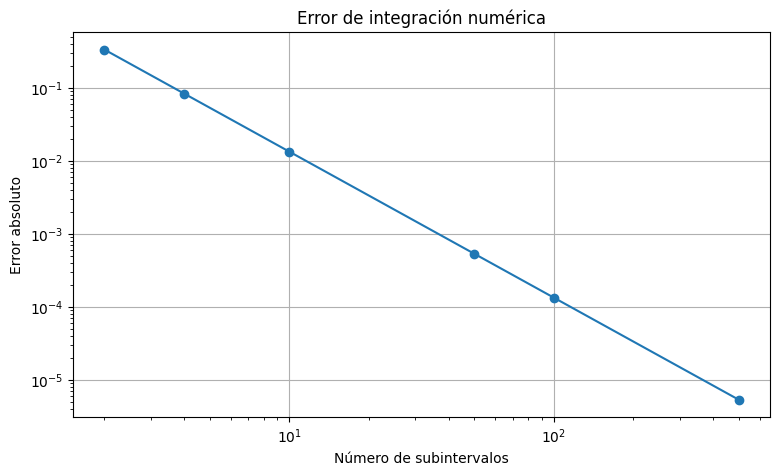

In [7]:
plt.figure(figsize=(9, 5))

plt.loglog(N_values, errors, marker="o")

plt.xlabel("Número de subintervalos")
plt.ylabel("Error absoluto")
plt.title("Error de integración numérica")
plt.grid(True)

plt.show()

Esto introduce una idea esencial:

$$
\boxed{\text{convergencia numérica}}
$$

No solamente queremos una respuesta.

Queremos saber:

> ¿Qué tan rápido se acerca nuestra aproximación a la solución exacta?

# 5.5 Simpson

La regla de Simpson utiliza aproximaciones cuadráticas.

Para un intervalo apropiado:

$$
\boxed{
\int_a^bf(x)dx
\approx
\frac{b-a}{6}
[
f(a)+4f(\frac{a+b}{2})+f(b)
]
}
$$

Suele ser mucho más precisa para funciones suaves.

# 5.6 Un ejemplo sin solución elemental

Considera:

$$
I=
\int_0^1e^{-x^2}dx
$$

No existe una antiderivada elemental.

Pero:

In [8]:
from scipy.integrate import quad

f = lambda x: np.exp(-x**2)

I, error = quad(f, 0, 1)

print("I =", I)
print("Error estimado =", error)

I = 0.7468241328124271
Error estimado = 8.291413475940725e-15


Resultado aproximadamente:

$$
\boxed{I\approx0.746824}
$$

Esto es exactamente el tipo de situación donde la computación científica se vuelve necesaria.

# 6. INTEGRALES IMPROPIAS

Ahora tenemos integrales donde:

1. el intervalo es infinito, o
2. la función se vuelve infinita.

# 6.1 Intervalo infinito

Por ejemplo:

$$
\int_0^\infty e^{-x}dx
$$

La definimos como:

$$
\lim_{b\rightarrow\infty}
\int_0^be^{-x}dx
$$

Calculamos:

$$
\int e^{-x}dx=-e^{-x}
$$

Entonces:

$$
\lim_{b\rightarrow\infty}
[-e^{-x}]_0^b
$$

$$
=
\lim_{b\rightarrow\infty}
(1-e^{-b})
$$

Como:

$$
e^{-b}\rightarrow0
$$

obtenemos:

$$
\boxed{1}
$$

# 6.2 Python

In [9]:
from scipy.integrate import quad

f = lambda x: np.exp(-x)

resultado, error = quad(f, 0, np.inf)

print(resultado)
print(error)

1.0000000000000002
5.842606742906004e-11


# 6.3 Visualización

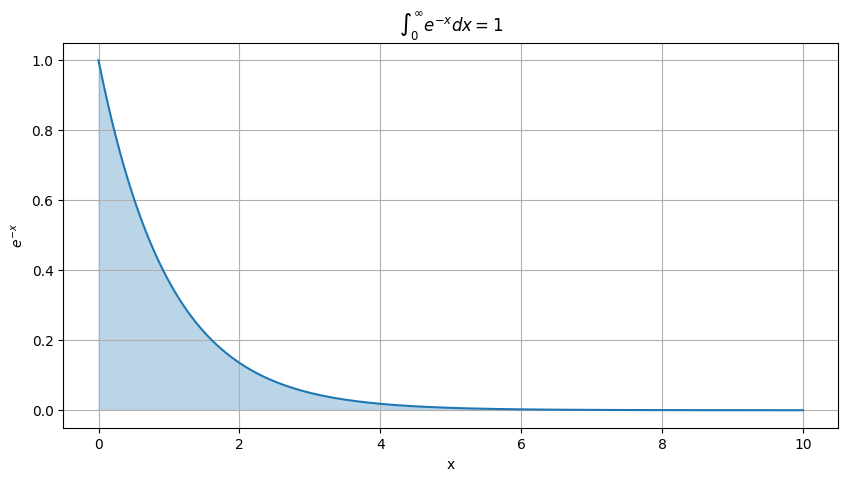

In [10]:
x = np.linspace(0, 10, 1000)

y = np.exp(-x)

plt.figure(figsize=(10, 5))

plt.plot(x, y)

plt.fill_between(x, y, alpha=0.3)

plt.xlabel("x")
plt.ylabel(r"$e^{-x}$")
plt.title(r"$\int_0^\infty e^{-x}dx=1$")
plt.grid(True)

plt.show()

La integral representa toda el área acumulada hasta infinito.

# 6.4 Integral impropia con singularidad

Considera:

$$
\int_0^1\frac1{\sqrt{x}}dx
$$

En:

$$
x=0
$$

la función se hace infinita.

Pero la integral puede converger.

La escribimos:

$$
\lim_{\epsilon\rightarrow0^+}
\int_\epsilon^1x^{-1/2}dx
$$

La antiderivada:

$$
2\sqrt{x}
$$

Entonces:

$$
\lim_{\epsilon\rightarrow0^+}
[2\sqrt{x}]_\epsilon^1
$$

$$
=
2-
2\sqrt{\epsilon}
$$

y por tanto:

$$
\boxed{2}
$$

# 6.5 Esto es importante

Que una función sea infinita en un punto **no implica automáticamente que la integral diverja**.

Por ejemplo:

$$
\int_0^1\frac1{\sqrt{x}}dx
$$

converge.

En cambio:

$$
\int_0^1\frac1{x}dx
$$

diverge.

Porque:

$$
\int_\epsilon^1\frac1x dx
=
-\ln\epsilon
$$

y:

$$
-\ln\epsilon\rightarrow\infty
$$

cuando:

$$
\epsilon\rightarrow0^+
$$

# 7. APLICACIÓN 1: DISTANCIA A PARTIR DE VELOCIDAD

Si conocemos:

$$
v(t)
$$

la distancia neta recorrida es:

$$
\boxed{
\Delta x=
\int_{t_1}^{t_2}v(t)dt
}
$$

# 7.1 Ejemplo

Supongamos:

$$
v(t)=4t^3-12t^2+9t
$$

entre:

$$
0\leq t\leq4
$$

Entonces:

$$
x(4)-x(0)
=
\int_0^4
(4t^3-12t^2+9t)dt
$$

In [11]:
t = sp.symbols("t")

v = 4*t**3 - 12*t**2 + 9*t

distance = sp.integrate(v, (t, 0, 4))

print(distance)

72


# 7.2 Gráfica

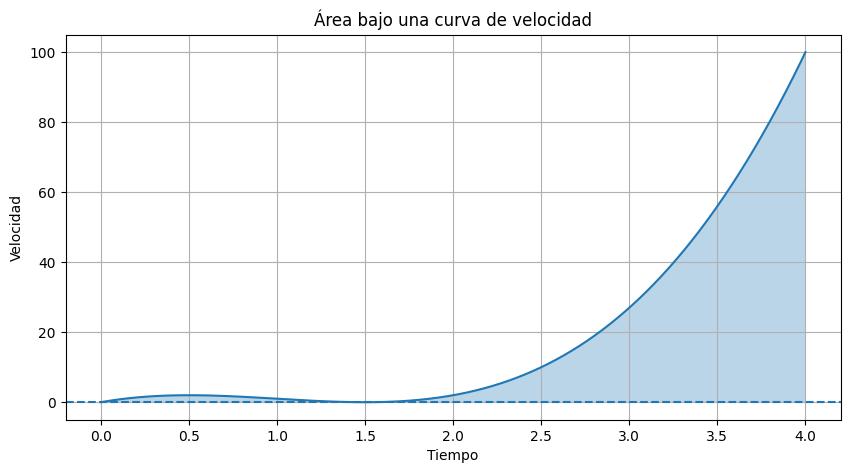

In [12]:
t = np.linspace(0, 4, 1000)

v = 4*t**3 - 12*t**2 + 9*t

plt.figure(figsize=(10, 5))

plt.plot(t, v)

plt.fill_between(t, v, where=(v >= 0), alpha=0.3)
plt.fill_between(t, v, where=(v < 0), alpha=0.3)

plt.axhline(0, linestyle="--")

plt.xlabel("Tiempo")
plt.ylabel("Velocidad")
plt.title("Área bajo una curva de velocidad")
plt.grid(True)

plt.show()

Observa que si la velocidad es negativa, la integral produce **desplazamiento neto**, no necesariamente distancia total.

Para distancia física total debemos integrar:

$$
\boxed{
\int |v(t)|dt
}
$$

Esta distinción es importante.

# 8. APLICACIÓN 2: MASA A PARTIR DE DENSIDAD

Si tenemos una densidad lineal:

$$
\rho(x)
$$

entonces la masa:

$$
\boxed{
M=\int_a^b\rho(x)dx
}
$$

# 8.1 Ejemplo

Una barra tiene:

$$
\rho(x)=5+2x^2
$$

para:

$$
0\leq x\leq3
$$

Entonces:

$$
M=
\int_0^3(5+2x^2)dx
$$

$$
=
\left[
5x+\frac{2x^3}{3}
\right]_0^3
$$

$$
=15+18
$$

$$
\boxed{M=33}
$$

# 8.2 Python

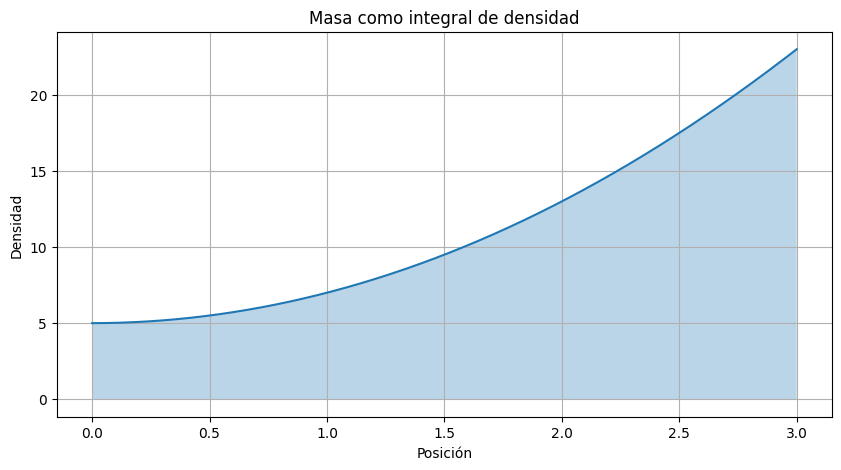

In [13]:
x = np.linspace(0, 3, 1000)

rho = 5 + 2*x**2

plt.figure(figsize=(10, 5))

plt.plot(x, rho)
plt.fill_between(x, rho, alpha=0.3)

plt.xlabel("Posición")
plt.ylabel("Densidad")
plt.title("Masa como integral de densidad")
plt.grid(True)

plt.show()

# 9. APLICACIÓN 3: TRABAJO

En física:

$$
W=\int F(x)dx
$$

Si la fuerza cambia con la posición, no puedes simplemente hacer:

$$
W=Fd
$$

utilizando una única fuerza.

# 9.1 Ejemplo

Supongamos:

$$
F(x)=x^2+3x
$$

entre:

$$
x=0
$$

y:

$$
x=5
$$

Entonces:

$$
W=
\int_0^5(x^2+3x)dx
$$

$$
=
\left[
\frac{x^3}{3}+\frac32x^2
\right]_0^5
$$

$$
=
\frac{125}{3}+\frac{75}{2}
$$

$$
\boxed{
W=\frac{475}{6}
}
$$

# 10. APLICACIÓN 4: PROBABILIDAD

Esta conexión es **muy importante para Machine Learning**.

Si una variable aleatoria continua tiene densidad:

$$
p(x)
$$

entonces:

$$
\boxed{
P(a\leq X\leq b)
=
\int_a^bp(x)dx
}
$$

# 10.1 Distribución normal

La densidad normal:

$$
p(x)=
\frac{1}{\sqrt{2\pi}}
e^{-x^2/2}
$$

Entonces:

$$
P(-1\leq X\leq1)
=
\int_{-1}^1
\frac1{\sqrt{2\pi}}
e^{-x^2/2}dx
$$

Python:

In [14]:
from scipy.integrate import quad

normal = lambda x: (
    1 / np.sqrt(2*np.pi)
    * np.exp(-x**2 / 2)
)

probabilidad, error = quad(normal, -1, 1)

print(probabilidad)

0.682689492137086


Obtendrás aproximadamente:

$$
0.6827
$$

Es decir, aproximadamente el 68.27 % de la masa de probabilidad está entre $(-1)$ y $(1)$.

# 10.2 Visualización

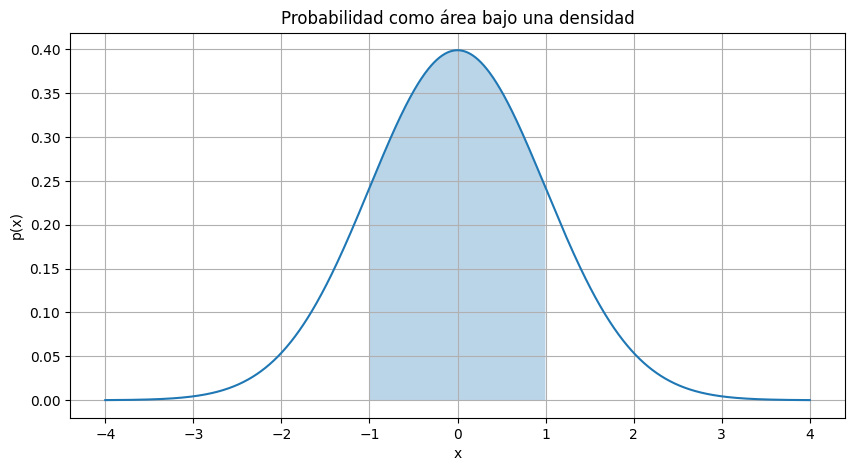

In [15]:
x = np.linspace(-4, 4, 1000)

y = (
    1 / np.sqrt(2*np.pi)
    * np.exp(-x**2 / 2)
)

plt.figure(figsize=(10, 5))

plt.plot(x, y)

mask = (x >= -1) & (x <= 1)

plt.fill_between(
    x[mask],
    y[mask],
    alpha=0.3
)

plt.xlabel("x")
plt.ylabel("p(x)")
plt.title("Probabilidad como área bajo una densidad")
plt.grid(True)

plt.show()

Aquí puedes ver una conexión directa:

$$
\boxed{
\text{integrales}
\rightarrow
\text{probabilidad}
\rightarrow
\text{estadística}
\rightarrow
\text{Machine Learning}
}
$$

# 11. APLICACIÓN 5: ENERGÍA

La energía cinética:

$$
E_k=\frac12mv^2
$$

Pero en sistemas continuos, la energía puede requerir integración.

Por ejemplo, una barra con densidad:

$$
\rho(x)
$$

y velocidad:

$$
v(x)
$$

puede tener energía cinética:

$$
\boxed{
E=
\frac12
\int
\rho(x)v(x)^2dx
}
$$

Este patrón:

$$
\int \text{densidad}\times\text{cantidad física}\,dx
$$

aparece constantemente en física computacional.

# 12. INTEGRACIÓN NUMÉRICA Y SCIENTIFIC MACHINE LEARNING

Aquí quiero que veas una conexión muy importante.

En matemáticas:

$$
I=\int_a^bf(x)dx
$$

Pero un ordenador no manipula realmente un continuo infinito.

Trabajamos con puntos:

$$
x_0,x_1,\ldots,x_N
$$

y aproximamos:

$$
I\approx
\sum_iw_if(x_i)
$$

Esto es cuadratura numérica.

# 12.1 Ejemplo

Supongamos:

$$
f(x)=e^{-x^2}\cos(10x)
$$

Esta función oscila rápidamente.

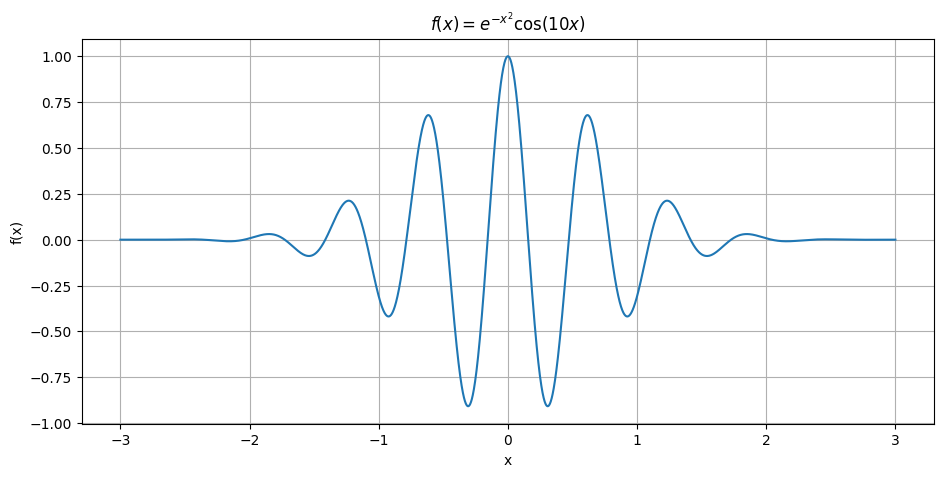

In [16]:
x = np.linspace(-3, 3, 5000)

f = np.exp(-x**2)*np.cos(10*x)

plt.figure(figsize=(11, 5))

plt.plot(x, f)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title(r"$f(x)=e^{-x^2}\cos(10x)$")
plt.grid(True)

plt.show()

Queremos:

$$
I=\int_{-3}^3e^{-x^2}\cos(10x)dx
$$

Numéricamente:

In [17]:
from scipy.integrate import quad

f = lambda x: np.exp(-x**2)*np.cos(10*x)

I, error = quad(f, -3, 3)

print("Integral =", I)
print("Error estimado =", error)

Integral = -1.963110913052302e-05
Error estimado = 1.2932250580092426e-14


Este tipo de integral puede aparecer en análisis de ondas y transformadas.

# 13. UN CONCEPTO MUY IMPORTANTE: INTEGRACIÓN VS DIFERENCIACIÓN NUMÉRICA

En SciML trabajarás continuamente con datos discretos.

Supongamos:

$$
x_0,x_1,x_2,\ldots
$$

y:

$$
f_0,f_1,f_2,\ldots
$$

Podemos aproximar derivadas mediante diferencias finitas:

$$
f'(x)
\approx
\frac{f(x+h)-f(x)}{h}
$$

y una integral mediante:

$$
\int_a^bf(x)dx
\approx
\sum_iw_if(x_i)
$$

Esto significa:

```text
FUNCIÓN CONTINUA
       │
       ▼
DISCRETIZACIÓN
       │
       ▼
x₀ x₁ x₂ x₃ ... xₙ
       │
       ├──────────────┐
       ▼              ▼
   DERIVACIÓN      INTEGRACIÓN
   NUMÉRICA        NUMÉRICA
       │              │
       └──────┬───────┘
              ▼
       MÉTODOS NUMÉRICOS
              │
              ▼
             SciML
```

# 14. UNA INTEGRAL MÁS PROFUNDA: NORMA DE UNA FUNCIÓN

Esto te será muy útil más adelante.

Podemos definir:

$$
\|f\|_2
=
\sqrt{
\int_a^b|f(x)|^2dx
}
$$

Por ejemplo:

$$
f(x)=\sin x
$$

Entonces:

$$
\|f\|_2
=
\sqrt{
\int_0^{2\pi}\sin^2x\,dx
}
$$

Como:

$$
\int_0^{2\pi}\sin^2x\,dx=\pi
$$

tenemos:

$$
\boxed{
\|f\|_2=\sqrt{\pi}
}
$$

¿Por qué te lo menciono?

Porque en SciML, Machine Learning y métodos numéricos constantemente se mide:

$$
\boxed{\text{error}}
$$

mediante normas.

Por ejemplo:

$$
\|u_{\text{pred}}-u_{\text{exact}}\|_2
$$

Eso es una integral.

# 15. ERROR INTEGRAL ENTRE DOS SOLUCIONES

Supongamos que tenemos:

$$
u(x)
$$

solución exacta y:

$$
\hat u(x)
$$

predicción de nuestro modelo.

Podemos definir:

$$
E=
\sqrt{
\int_a^b
|u(x)-\hat u(x)|^2dx
}
$$

Esto es conceptualmente muy cercano a lo que posteriormente utilizarás para evaluar modelos científicos.

En Python:

In [18]:
x = np.linspace(-5, 5, 2000)

u = np.exp(-x**2)
u_pred = np.exp(-0.95*x**2)

error = np.sqrt(
    np.trapezoid((u - u_pred)**2, x)
)

print("Error L2 =", error)

Error L2 = 0.025023552898439952


Aquí acabas de usar:

$$
\boxed{
\text{integración}
+
\text{norma}
+
\text{error}
}
$$

# 16. INTEGRAL DOBLE

Aunque no esté explícitamente en tu lista, conviene que tengas una primera intuición.

Una integral doble:

$$
\iint_D f(x,y)dA
$$

permite acumular cantidades sobre una superficie.

Por ejemplo, una densidad superficial:

$$
\rho(x,y)
$$

produce una masa:

$$
\boxed{
M=
\iint_D\rho(x,y)dA
}
$$

Esto será muy importante cuando llegues a:

* campos;
* PDE;
* mecánica;
* fluidos;
* electromagnetismo;
* elementos finitos.

# 17. CONEXIÓN CON ECUACIONES DIFERENCIALES

Supongamos:

$$
\frac{du}{dt}=f(t)
$$

Para obtener $u(t)$, integramos:

$$
u(t)
=
u(0)+
\int_0^t f(s)ds
$$

Esto es fundamental.

Por ejemplo:

$$
\frac{dv}{dt}=a(t)
$$

entonces:

$$
v(t)
=
v(0)+
\int_0^ta(s)ds
$$

Y:

$$
x(t)
=
x(0)+
\int_0^tv(s)ds
$$

Por tanto:

$$
\boxed{
\text{aceleración}
\rightarrow
\text{integración}
\rightarrow
\text{velocidad}
\rightarrow
\text{integración}
\rightarrow
\text{posición}
}
$$

Esta es una de las razones por las que el cálculo integral es fundamental para simulación científica.

# 18. CONEXIÓN CON SCIENTIFIC MACHINE LEARNING

Ahora llegamos a la parte más importante para tu objetivo.

Supongamos una PDE:

$$
\frac{\partial u}{\partial t}
=
\alpha
\frac{\partial^2u}{\partial x^2}
$$

En SciML podemos tener una red neuronal:

$$
u_\theta(x,t)
$$

que intenta aproximar la solución.

Pero necesitamos medir cuánto viola la ecuación.

Construimos un residual:

$$
r_\theta(x,t)
=
\frac{\partial u_\theta}{\partial t}
-
\alpha
\frac{\partial^2u_\theta}{\partial x^2}
$$

Y podemos construir una pérdida:

$$
\boxed{
L=
\int
|r_\theta(x,t)|^2dxdt
}
$$

Mira lo que acaba de ocurrir:

$$
\boxed{
\text{derivadas}
+
\text{integrales}
+
\text{optimización}
+
\text{red neuronal}
}
$$

Eso es precisamente una de las ideas centrales detrás de muchas técnicas de **Scientific Machine Learning**.

| **Inicio**         | **atrás 2**                          | **Siguiente 4**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./1_2_Calculo_diferencial.ipynb) | [⏩](./1_4_Series.ipynb) |